# 랭그래프를 활용한 멀티에이전트 RAG 만들기

### 필요한 경우에만 검색하는 RAG

앞서 chap09에서 만든 RAG는 사용자 입력을 받으면 리트리버로 관련 문서를 검색하고, 이를 바탕으로 답변을 생성합니다. 하지만 “잘 지냈어?”라는 인사나 “잘 찾아왔네. 고마워.”라는 감사 표현에는 문서 검색이 필요하지 않습니다.  
이런 입력에도 검색을 수행하면 처리 시간이 늘고, 불필요한 문서를 모델에 전달하면서 토큰을 사용하게 됩니다.

LangGraph를 활용하면 검색이 필요한지 먼저 판단하고, 필요한 경우에만 문서를 검색하는 흐름을 만들 수 있습니다. 검색 이후에도 청크의 관련성을 평가하여 답변에 사용할 자료를 선별할 수 있습니다.


## 두 번의 판단

| 단계 | 판단할 질문 | 역할 |
|---|---|---|
| **검색 전: 라우팅** | 문서 검색이 필요한가? | 검색 경로와 일상 대화 경로 선택 |
| **검색 후: 청크 평가** | 이 청크가 질문과 관련 있는가? | 답변에 사용할 자료 선별 |

1. **검색 여부 결정(라우팅)**  
   사용자 의도를 분석해 자료가 필요하면 검색 경로로, 인사·감사 표현이면 `casual_talk`으로 보냅니다. 감사와 추가 질문이 섞인 경우에는 전체 의도를 기준으로 판단합니다.

2. **검색한 청크의 관련성 평가**  
   검색 결과가 질문에 유용하다는 보장은 없습니다. `grade_documents`가 관련 청크만 선별하고, `generate`가 이를 근거로 답변을 생성합니다.

## 실행 구조
    사용자 입력
        │
        ▼
    라우터: 검색이 필요한가?
        │
        ├─ 아니요
        │    └─ casual_talk → 일상 답변 → 종료
        │
        └─ 예
             └─ retrieve → grade_documents → generate → 종료
                청크 검색    관련 청크 선별      근거 기반 답변

| 구성 요소 | 하는 일 | 결과 |
|---|---|---|
| 라우터 | 사용자 의도 분석 | 실행 경로 선택 |
| `retrieve` | 관련 청크 검색 | 후보 문서 목록 |
| `grade_documents` | 청크별 관련성 평가 | 선별된 문서 목록 |
| `generate` | 선별된 문서로 답변 생성 | 문서 기반 답변 |
| `casual_talk` | 검색 없이 대화에 응답 | 일상 답변 |

In [11]:
from glob import glob 

for g in glob('data/*.pdf'):
    print(g)

data\2040_seoul_plan.pdf
data\OneNYC_2050_Strategic_Plan.pdf


In [12]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

def read_pdf_and_split_text(pdf_path, chunk_size=1000, chunk_overlap=100):
    """
    주어진 PDF 파일을 읽고 텍스트를 분할합니다.
    매개변수:
        pdf_path (str): PDF 파일의 경로.
        chunk_size (int, 선택적): 각 텍스트 청크의 크기. 기본값은 1000입니다.
        chunk_overlap (int, 선택적): 청크 간의 중첩 크기. 기본값은 100입니다.
    반환값:
        list: 분할된 텍스트 청크의 리스트.
    """
    print(f"PDF: {pdf_path} -----------------------------")

    pdf_loader = PyPDFLoader(pdf_path)
    data_from_pdf = pdf_loader.load()

    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size, chunk_overlap=chunk_overlap
    )

    splits = text_splitter.split_documents(data_from_pdf)
    
    print(f"Number of splits: {len(splits)}\n")
    return splits


In [13]:
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
import os

##### Vectorstore 설정 #####
embedding = OpenAIEmbeddings(model='text-embedding-3-large')

persist_directory='chroma_store'

if os.path.exists(persist_directory):
    print("Loading existing Chroma store")
    vectorstore = Chroma(
        persist_directory=persist_directory, 
        embedding_function=embedding
    )
else:
    print("Creating new Chroma store")
    
    vectorstore = None
    for g in glob('data/*.pdf'):
        chunks = read_pdf_and_split_text(g)
        # 100개씩 나눠서 저장
        for i in range(0, len(chunks), 100):
            if vectorstore is None:
                vectorstore = Chroma.from_documents(
                    documents=chunks[i:i+100],
                    embedding=embedding,
                    persist_directory=persist_directory
                )
            else:
                vectorstore.add_documents(
                    documents=chunks[i:i+100]
                )


Loading existing Chroma store


## 검색 품질: 비슷한 문서와 답이 있는 문서는 다르다

`k=5`는 후보 수의 상한이다. 관련 있는 근거가 다섯 개 존재한다는 뜻은 아니다. 이 코드에는 유사도 임계값을 별도로 두지 않아, 질문에 맞는 자료가 부족해도 상대적으로 가까운 청크를 가져올 수 있다.

**생성기를 보기 전에 검색 결과만으로 판단해 보자.**

- 질문의 대상·주제·시점이 후보 본문과 맞는가?
- 답에 필요한 수치·조건·예외가 함께 있는가?
- 다섯 후보가 비슷한 내용을 반복하는가, 서로 보완하는가?

검색에서 빠진 근거를 뒤의 관련성 필터가 되살릴 수는 없다. `k`를 늘리면 근거를 찾을 기회와 함께 무관한 후보·평가 비용도 늘어난다. 같은 질문으로 후보의 본문과 출처를 비교해야 이 절충을 볼 수 있다.

In [14]:
retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

chunks = retriever.invoke("서울 온실가스 저감 계획")

for chunk in chunks:
    print(chunk.metadata)
    print(chunk.page_content)


In [15]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-6-luna")
model.invoke('안녕하세요!')

AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 9, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EaFecNmSb4DsvhGKILNZpbRNVgisF', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14dec-39ff-7790-beae-36f1deb14fa0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 14, 'total_tokens': 23, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

## 라우팅: 분기 형식과 분기 판단을 분리하기

라우터의 결과는 사용자에게 보여 줄 답변이 아니라 **다음 실행 경로를 고르는 제어값**이다. 자유로운 문장 대신 제한된 선택지를 받으면 그래프가 그 값을 분기에 사용할 수 있다.

| 검토할 층 | 이 예제의 장치 | 보장하지 않는 것 |
|---|---|---|
| 출력 형식 | `RouteQuery`와 `Literal` | 올바른 경로 선택 |
| 판단 기준 | 스키마 설명과 라우팅 프롬프트 | 모호한 입력의 일관된 분류 |
| 실제 이동 | 뒤에서 정의할 경로 매핑 | 선택된 경로의 답변 품질 |

**생각할 문제:** “서울”이라는 단어가 있으면 항상 검색해야 할까? 도시 이름보다 *저장된 자료가 답변에 필요한 요청인지*가 기준이다. 저장소 범위 밖의 전문 질문도 들어올 수 있지만, 현재 선택지는 검색과 일상 대화 두 개뿐이다.

In [16]:
# Router 설정
from langchain_core.prompts import ChatPromptTemplate
from typing import Literal # 문자열 리터럴 타입을 지원하는 typing 모듈의 클래스
from pydantic import BaseModel, Field

# Data model
class RouteQuery(BaseModel):
    """사용자 쿼리를 가장 관련성이 높은 데이터 소스로 라우팅합니다."""
    
    datasource: Literal["vectorstore", "casual_talk"] = Field(
        ...,
        description="""
        사용자 질문에 따라 casual_talk 또는 vectorstore로 라우팅합니다.
        - casual_talk: 일상 대화를 위한 데이터 소스. 사용자가 일상적인 질문을 할 때 사용합니다.
        - vectorstore: 사용자 질문에 답하기 위해 RAG로 vectorstore 검색이 필요한 경우 사용합니다.
        """,
    )

### 라우터 프롬프트는 저장소의 범위를 설명한다

라우터는 PDF 전체를 읽고 분기하지 않는다. 현재 질문과 “서울·뉴욕 발전 계획 문서가 있다”는 설명으로 판단한다. 따라서 **문서를 교체하면서 라우팅 설명을 그대로 두면 저장소와 판단 기준이 어긋난다.**

체인의 데이터 흐름은 다음과 같다.

```text
질문 → 프롬프트에 명시된 자료 범위와 대조 → RouteQuery → 경로 이름
```

감사·인사를 일상 대화로 처리하려는 의도는 있지만, 현재 프롬프트에 모든 경계 사례가 명시되어 있지는 않다. 구조화된 출력은 이런 의미 판단을 대신하지 않는다. 다음 실험에서 경계 사례를 확인한다.

In [17]:
# 특정 모델을 structured output (구조화된 출력)과 함께 사용하기 위해 설정
structured_llm_router = model.with_structured_output(RouteQuery)

router_system = """
당신은 사용자의 질문을 vectorstore 또는 casual_talk으로 라우팅하는 전문가입니다.
- vectorstore에는 서울, 뉴욕의 발전계획과 관련된 문서가 포함되어 있습니다. 이 주제에 대한 질문에는 vectorstore를 사용하십시오.
- 사용자의 질문이 일상 대화에 관련된 경우 casual_talk을 사용하십시오.
"""

# 시스템 메시지와 사용자의 질문을 포함하는 프롬프트 템플릿 생성
route_prompt = ChatPromptTemplate.from_messages([
    ("system", router_system),
    ("human", "{question}"),
])

# 라우터 프롬프트와 구조화된 출력 모델을 결합한 객체
question_router = route_prompt | structured_llm_router


### 분기 실험: 정답 경로를 먼저 정하고 비교하기

쉬운 두 예제만 통과하면 키워드에 의존하는 라우터도 잘 작동하는 것처럼 보인다. 아래 입력을 기준으로 예상 경로를 정한 뒤 실제 선택을 비교해 보자.

| 시험 입력 | 기대하는 판단 | 관찰할 오류 |
|---|---|---|
| “서울 온실가스 저감 계획은?” | 저장 자료가 필요함 | 필요한 검색을 건너뜀 |
| “잘 지냈어?” | 일상 대화 | 불필요한 검색 |
| “서울 여행은 어때?” | 자료 범위와 요청 의도를 함께 판단 | 도시 이름만으로 검색 |
| “잘 찾아왔네. 고마워.” | 새 자료 요청이 없는 감사 표현 | 검색 행위를 언급했다는 이유로 재검색 |
| “고마워. 뉴욕 계획도 비교해 줘.” | 감사와 별개로 새 자료 요청이 있음 | 감사 표현만 보고 검색 생략 |

이 노트북은 현재 입력만 전달하므로, 감사 표현을 분류할 수 있어도 앞선 답변의 내용을 기억하는 것은 아니다. “그 계획도 비교해 줘”처럼 선행 문맥이 필요한 요청은 별도 문제로 남는다.

In [18]:
print(
    question_router.invoke({
        "question": "서울 온실가스 저감 계획은 무엇인가요?"
    })
)

print(question_router.invoke({"question": "잘 지냈어?"}))

datasource='vectorstore'
datasource='casual_talk'


## 관련성 평가: 검색 후보를 줄이는 두 번째 판단

벡터 검색은 의미상 가까운 후보를 찾는다. 평가자는 질문과 후보 본문을 함께 읽고 이번 답변에 쓸 만한 후보를 고른다. 예를 들어 자율주행 계획을 묻는데 녹지 확대 청크가 검색되었다면, 같은 도시의 계획이라는 공통점만으로는 충분하지 않다.

```text
검색에서 놓친 근거 → 평가자가 복구할 수 없음
검색에 섞인 무관한 후보 → 평가자가 걸러낼 수 있음
```

`yes`가 뜻하는 것은 이 프롬프트 기준의 **관련성**이다. 문서의 사실성·최신성·신뢰성이나 답변에 필요한 근거의 충분성까지 검증한 것은 아니다. 이 구분을 잊으면 필터를 통과한 문서에 과도한 신뢰를 주게 된다.

In [19]:
from langchain_core.prompts import PromptTemplate

class GradeDocuments(BaseModel):
    """검색된 문서가 질문과 관련성 있는지 yes 또는 no로 평가합니다."""

    binary_score: Literal["yes", "no"] = Field(
        description="문서가 질문과 관련이 있는지 여부를 'yes' 또는 'no'로 평가합니다."
    )

structured_llm_grader = model.with_structured_output(GradeDocuments)

### 평가 기준의 절충: 넓게 남길 것인가, 엄격히 버릴 것인가

현재 프롬프트는 관련 키워드나 의미가 있으면 남기고 엄격한 테스트를 요구하지 않는다. 이는 유용한 근거를 성급하게 버리지 않으려는 기준이지만, 주제만 비슷한 후보도 통과시킬 수 있다.

| 오류 | 뒤 단계에 미치는 영향 | 확인할 질문 |
|---|---|---|
| 필요한 문서를 `no`로 판정 | 답변 근거 손실 | 질문에 직접 답하는 문장이 있었는가? |
| 무관한 문서를 `yes`로 판정 | 문맥 잡음과 입력 토큰 증가 | 주제만 같은가, 실제 요청에도 도움이 되는가? |

판정 기준을 바꿀 때는 같은 질문·같은 후보를 유지하고 비교한다. 후보 검색까지 바뀌면 평가 프롬프트의 효과를 구분하기 어렵다.

In [20]:
grader_prompt = PromptTemplate.from_template("""
당신은 검색된 문서가 사용자 질문과 관련이 있는지 평가하는 평가자입니다. \n 
문서에 사용자 질문과 관련된 키워드 또는 의미가 포함되어 있으면, 해당 문서를 관련성이 있다고 평가하십시오. \n
엄격한 테스트가 필요하지 않습니다. 목표는 잘못된 검색 결과를 걸러내는 것입니다. \n
문서가 질문과 관련이 있는지 여부를 나타내기 위해 'yes' 또는 'no'로 이진 점수를 부여하십시오.
                                             
Retrieved document: \n {document} \n\n 
User question: {question}
""")

retrieval_grader = grader_prompt | structured_llm_grader
question = "서울시 자율주행 관련 계획"
documents = retriever.invoke(question)

for doc in documents:
    print(doc)


In [21]:
filtered_docs = []

for i, doc in enumerate(documents):
    print(f"Document {i + 1}:")
    is_relevant = retrieval_grader.invoke({"question": question, "document": doc.page_content})
    print(is_relevant)
    print(doc.page_content[:200])
    print("=================================\n\n")

    if is_relevant.binary_score == "yes":
        filtered_docs.append(doc)

print(f"Filtered documents: {len(filtered_docs)}")


Filtered documents: 0


## 생성 품질: 유창함보다 주장과 근거의 연결

RAG에서 검색은 모델의 지식을 갱신하는 학습이 아니라 **이번 호출의 입력에 근거를 넣는 작업**이다. 따라서 좋은 답변인지 확인하려면 각 주장이 제공된 문서에서 나왔는지 추적해야 한다.

| 답변에서 확인할 것 | 합격 기준 |
|---|---|
| 계획·수치·시점 | 문서의 표현과 조건이 일치함 |
| 여러 문서의 종합 | 출처가 다른 내용을 섞어 새로운 사실로 단정하지 않음 |
| 근거가 없는 부분 | 문서에 없는 내용을 근거 있는 사실처럼 덧붙이지 않음 |

현재는 `Document` 목록을 `context`에 직접 넣어 객체의 문자열 표현을 전달한다. 본문·출처를 명시적으로 편집한 문맥이 아니므로 실제 프롬프트를 살펴보면 입력 구성을 더 잘 이해할 수 있다. 메타데이터가 들어 있다고 출처 인용이 자동으로 보장되지는 않는다.

**빈 문맥 실험:** 근거가 하나도 남지 않았을 때 어떻게 답할지 예상해 보자. 현재 프롬프트에는 답변 보류 정책이나 인용 형식이 없다. “context에 기반하라”는 지시만으로 근거 없는 생성을 방지했다고 볼 수 없다.

In [22]:
### Generate
# PromptTemplate을 사용하여 RAG를 위한 프롬프트를 생성합니다.

rag_generate_system = """
너는 사용자의 질문에 대해 주어진 context에 기반하여 답변하는 도시 계획 전문가이다. 
주어진 context는 vectorstore에서 검색된 결과이다. 
주어진 context를 기반으로 사용자의 question에 대해 답변하라.

=================================
question: {question}
context: {context}
"""

# PromptTemplate을 생성하여 question과 context를 포맷팅
rag_prompt = PromptTemplate(
    input_variables=["question", "context"],
    template=rag_generate_system
)

# rag chain
rag_chain = rag_prompt | model 

# 사용자 질문과 검색된 문서를 입력으로 사용하여 RAG를 실행
question = "서울시 자율주행 관련 계획"

rag_chain.invoke({"question": question, "context": filtered_docs})


AIMessage(content='제공된 context가 비어 있어 서울시 자율주행 관련 계획을 확인하거나 정확히 요약할 수 없습니다. 관련 계획 문서나 검색 결과를 제공해 주시면, 주요 사업·추진 일정·대상 지역 등을 정리해 드리겠습니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 142, 'prompt_tokens': 74, 'total_tokens': 216, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 75, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EaFeiJ1O3kDErQebmhXfRaiJNaDBF', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14dec-53b4-7d42-bb3d-a6840c949e21-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 74, 'output_tokens': 142, 'total_tokens': 216, 'input_token_details': {'audio': 0, 'cache_read': 0, '

## 상태 설계

상태는 각 노드가 읽고 쓰는 공통 작업 공간이다. 그래프를 이해할 때 함수 본문보다 먼저 **어떤 값이 언제 생기고, 어디서 교체되는지** 그려 보자.

| 상태 키 | 최초 생성·갱신 지점 | 실제 값과 수명 |
|---|---|---|
| `question` | 실행 입력 | 현재 요청의 문자열 |
| `documents` | 검색 → 평가 | `Document` 후보 목록 → 선별 목록으로 교체 |
| `generation` | 생성 또는 일상 대화 | 모델이 반환한 `AIMessage` |

일반 노드는 상태 갱신 딕셔너리를 반환한다. 별도 reducer가 없는 이 예제의 키는 새 값으로 교체되고, 반환하지 않은 키는 유지된다. 전체 상태를 매번 다시 반환할 필요는 없다.

**선언과 실제 값의 불일치:** 아래의 `List[str]`, `str` 표기와 달리 실행 함수는 문서 객체 목록과 메시지 객체를 넣는다. `TypedDict`가 이를 문자열로 변환하지는 않는다. 이후 코드를 수정한다면 타입을 실제 객체에 맞추거나 값을 문자열로 변환하는 방식 중 하나로 계약을 통일해야 한다. 현재 코드의 타입 표기를 그대로 실행 결과의 자료형으로 해석하지 말자.

In [23]:
from typing import List
from typing_extensions import TypedDict

class GraphState(TypedDict):
    question: str   # 사용자 질문
    generation: str # LLM 생성 결과
    documents: List[str] # 검색된 문서


### 분기 함수와 일반 노드의 반환값을 구분하기

| 구분 | 반환값 | 그래프에서의 의미 |
|---|---|---|
| `route_question` | 경로 이름 문자열 | 다음에 갈 노드 선택 |
| `retrieve` 등 일반 노드 | 상태 갱신 딕셔너리 | 다음 단계가 읽을 데이터 갱신 |

`vectorstore`는 여기서 분기 라벨이며 실행할 노드 이름 `retrieve`와 뒤의 매핑으로 연결된다. 함수의 주석·독스트링보다 실제 반환문과 연결 방식을 기준으로 읽어야 한다. 아래 독스트링의 딕셔너리 반환 설명은 실제 문자열 반환과 다르다.

In [24]:
def route_question(state): 
    """
    사용자 질문을 vectorstore 또는 casual_talk로 라우팅합니다.
    
    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 라우팅된 데이터 소스와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------ROUTE------')
    question = state['question']
    route = question_router.invoke({"question": question})

    
    print(f"---Routing to {route.datasource}---")
    return route.datasource   

### 검색 노드: 후보를 상태에 남기는 이유

검색 결과를 상태에 기록하면 평가 노드는 **방금 검색한 동일 후보**를 이어받는다. 평가 단계에서 다시 검색하면 후보 변화와 평가 기준의 영향을 구분하기 어렵다.

이 경계에서 확인할 것은 답변 문장이 아니라 후보 본문과 메타데이터다. 생성 결과가 나쁠 때 이 시점의 후보부터 확인하면 “근거를 못 찾음”과 “찾은 근거를 잘못 사용함”을 구분할 수 있다.

In [25]:
def retrieve(state): 
    """
    vectorstore에서 질문에 대한 문서를 검색합니다.
    
    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 검색된 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------RETRIEVE------')
    question = state['question']

    # Retrieve documents
    documents = retriever.invoke(question)
    return {"documents": documents, "question": question}

### 평가 노드: 상태를 덮어쓸 때 사라지는 정보

평가 후 `documents`에는 통과한 문서만 남는다. 따라서 최종 상태만 보면 **처음의 후보 수, 탈락 문서, 각 판정**을 복원할 수 없다. 이 실습에서는 앞의 단독 평가 출력을 이용해 선별 과정을 확인한다.

복습할 때는 “최종 문서가 없다”는 결과를 두 경우로 나눠 보자. 검색부터 비어 있었는지, 검색한 후보를 평가가 모두 버렸는지에 따라 조사할 단계가 다르다. 현재 연결은 두 경우 모두 생성 노드로 이어진다.

In [26]:
def grade_documents(state):
    """
    검색된 문서를 평가하여 질문과 관련성이 있는지 확인합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 관련성이 있는 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------GRADE------')
    question = state['question']
    documents = state['documents']
    filtered_docs = []

    for i, doc in enumerate(documents):
        is_relevant = retrieval_grader.invoke({"question": question, "document": doc.page_content})
        if is_relevant.binary_score == "yes":
            filtered_docs.append(doc)
    return {"documents": filtered_docs, "question": question}  

### 생성 노드: 답변까지의 책임 경계

라우터의 올바른 선택, 충분한 검색, 적절한 필터링은 각각 필요한 조건이지만 최종 답변의 정확성을 보장하지는 않는다. 생성 단계에서는 **선별된 근거와 실제 답변의 주장**을 대조한다.

결과의 `generation`은 메시지 객체이므로 본문은 `.content`로 확인한다. 그래프가 정상 종료했다는 사실과 근거에 충실한 답변을 만들었다는 평가는 별개다.

In [27]:
def generate(state):
    """
    LLM을 사용하여 문서와 사용자 질문에 대한 답변을 생성합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): LLM 생성 결과와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------GENERATE------')
    question = state['question']
    documents = state['documents']
    generation = rag_chain.invoke({"question": question, "context": documents})
    return {
        "documents": documents,
        "question": question,
        "generation": generation
    }

### 일상 대화 경로: 검색 생략의 이득과 오분류의 손실

이 경로는 질문 임베딩·문서 검색·후보 평가를 생략한다. 그래도 라우터와 일상 답변 모델은 호출하므로 “검색 없음”이 “모델 호출 없음”을 뜻하지는 않는다.

**오분류의 비대칭성:** 인사를 검색 경로로 보내면 불필요한 비용과 문맥이 생긴다. 자료 질문을 일상 경로로 보내면 필요한 근거 자체가 전달되지 않는다. 라우팅 실험에서 두 오류를 따로 기록해야 하는 이유다.

이 함수에는 이전 메시지를 전달하는 처리가 없다. 개별 호출에서 자연스럽게 답하는 기능과, 여러 턴의 대화를 기억하는 기능을 구분하자.

In [28]:
def casual_talk(state):
    """
    일상 대화를 위한 답변을 생성합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 일상 대화 결과와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------CASUAL TALK------')
    question = state['question']
    generation = model.invoke(question)
    return {
        "question": question,
        "generation": generation
    }

In [29]:
from langgraph.graph import START, StateGraph, END

workflow = StateGraph(GraphState)

In [30]:
# 노드를 정의 
workflow.add_node("retrieve", retrieve)
workflow.add_node("grade_documents", grade_documents)
workflow.add_node("generate", generate)
workflow.add_node("casual_talk", casual_talk)

In [31]:
# graph를 정의
workflow.add_conditional_edges(
    START, 
    route_question,
    {
        "vectorstore": "retrieve",
        "casual_talk": "casual_talk"
    }
)
workflow.add_edge("casual_talk", END)
workflow.add_edge("retrieve", "grade_documents")
workflow.add_edge("grade_documents", "generate")
workflow.add_edge("generate", END)

app = workflow.compile() # workflow를 컴파일

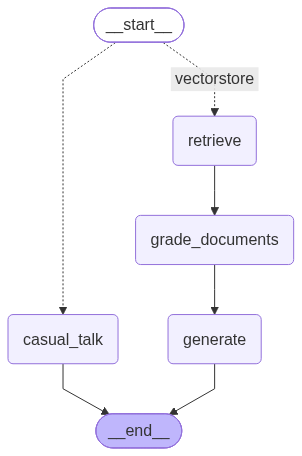

In [32]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    #  실패 시 통과
    pass


## 검증

도시 계획 요청의 예상 로그는 `ROUTE → RETRIEVE → GRADE → GENERATE`다. 검증은 두 단계로 나눈다.

1. **제어 흐름:** 의도한 노드가 실행되었는가?
2. **내용 품질:** 남은 문서가 질문에 답하며, 생성된 주장에 실제 근거가 있는가?

경로가 맞아도 답이 나쁠 수 있다. 그때는 후보에 근거가 있었는지 → 평가에서 버렸는지 → 생성에서 왜곡했는지 순으로 확인한다. 최종 상태의 문서는 평가 후 목록이므로, 탈락 후보는 앞의 단독 실험에서 비교한다.

In [33]:
inputs = {
    "question": "서울시 자율주행 계획"
}

app.invoke(inputs) # workflow를 실행합니다.

------ROUTE------
---Routing to vectorstore---
------RETRIEVE------
------GRADE------
------GENERATE------


{'question': '서울시 자율주행 계획',
 'generation': AIMessage(content='제공된 context가 비어 있어 서울시의 자율주행 계획을 구체적으로 설명할 근거가 없습니다. 관련 계획서나 검색 결과를 보내 주시면 **추진 목표, 운행 구역·노선, 서비스, 기반시설, 추진 일정**을 중심으로 정리해 드리겠습니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 198, 'prompt_tokens': 73, 'total_tokens': 271, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 121, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EaFepYrlfw6JyR7csvStGv5caN4o9', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14dec-6dbb-7a00-a5cb-f6ead0579c82-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 73, 'output_tokens': 198, 'total_tokens': 

### 일상 입력 검증: 실행되지 않아야 할 단계도 확인하기

인사말의 예상 경로는 `ROUTE → CASUAL TALK`이다. 자연스러운 답변만 확인하지 말고 `RETRIEVE`, `GRADE` 로그가 없는지도 확인한다.

감사 표현만 있는 입력과, 감사 뒤에 새 자료 요청이 붙은 입력을 비교해 보자. 전자는 검색 생략을, 후자는 새 요청에 필요한 검색을 기대한다. 각 `invoke()`에는 현재 질문만 전달되므로, 앞선 실행을 모델이 기억한다고 가정해서는 안 된다.

In [34]:
inputs = {
    "question": "잘 지내고 있어?"
}

app.invoke(inputs) # workflow를 실행합니다.

------ROUTE------
---Routing to casual_talk---
------CASUAL TALK------


{'question': '잘 지내고 있어?',
 'generation': AIMessage(content='응, 잘 지내고 있어! 너는 요즘 어때? 😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 12, 'total_tokens': 113, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 76, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EaFeuaBk57HvMN0mMou44qiM3w3js', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14dec-82f1-7cb3-84dc-38972082ddc5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 12, 'output_tokens': 101, 'total_tokens': 113, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'aud

In [35]:
inputs = {
    "question": "서울시의 자율주행 차량 관련 계획은 무엇이 있나요?"
}

for msg, meta in app.stream(inputs, stream_mode='messages'):
    print(msg.content, end='')


------ROUTE------
{"datasource":"vectorstore"}---Routing to vectorstore---
------RETRIEVE------


c:\Users\Unreon\Documents\Git\learn_do_it_llm_agent\chap13\.venv\Lib\site-packages\pydantic\main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=RouteQuery(datasource='vectorstore'), input_type=RouteQuery])
  return self.__pydantic_serializer__.to_python(


------GRADE------
------GENERATE------
제공된 context에 관련 자료가 없어, 서울시의 자율주행 차량 관련 계획을 확인해 답변하기 어렵습니다. 관련 문서나 검색 결과를 보내 주시면 그 내용을 바탕으로 핵심 계획을 정리해 드리겠습니다.